In [56]:
from src.dataset import split_into_val_dataset, load_raw_dataset, loader_train_val_test
from src.model import training_phase, test_phase
from src import config, utility, log, class_name, visualize

from torchvision.datasets import OxfordIIITPet
from torch.utils.data import DataLoader
import torchvision.transforms as transform
from torchvision.models import resnet18, resnet50
from torchsummary import summary
import torch.nn as nn
import torch.optim as optim
from pathlib import Path
from torch.utils.tensorboard import SummaryWriter


In [57]:
# Config in this section
RESULT_NAME = "resnet18_baseline"
DATA_PATH = "data"
IMAGE_SHAPE = (224, 224)
CLASS_NAME = class_name.OXFORD_III_PET
SAVE_WEIGHT = Path(f"weights/{RESULT_NAME}.pt")
WRITER = SummaryWriter(f"runs/{RESULT_NAME}")

Thiết lập cố định (để so sánh công bằng)

Những thứ sau phải **giống hệt** giữa baseline và các thí nghiệm transfer learning:

- Seed (ví dụ `42`) và cách chia train/val/test.
- Input size 224×224 và cách chuẩn hóa (dùng mean/std ImageNet cho mọi model).
- Augmentation, số epoch, cách tính metric.

Nếu có điểm nào khác (ví dụ optimizer, learning rate), phải ghi rõ lý do trong báo cáo.

In [58]:
# Creation functions
log.log_creation()
utility.set_seed()

================================ Configration ================================
Device              : cuda
GPU                 : NVIDIA GeForce RTX 4060 Laptop GPU
VRAM                : 8.6 GB
Seed                : 248
Workers             : 8
Batch size          : 32



# Baseline CNN trên Oxford-IIIT Pets
> Tài liệu mở đầu cho Practice 2: làm mốc so sánh trước khi thử transfer learning với ResNet.

## 1. Mục tiêu
Xây một CNN nhỏ, train from scratch trên Oxford-IIIT Pets và lưu lại kết quả để có mốc so sánh. Sau này khi fine-tune model pre-trained, ta trả lời được câu hỏi: transfer learning tốt hơn baseline bao nhiêu, đổi lại tốn thêm bao nhiêu compute?

Baseline không cần accuracy cao. Nó cần chạy nhanh, tái lập được và ghi lại đầy đủ.

## 2. Vì sao chọn Oxford-IIIT Pets

| Lý do                                     | Giải thích                                                                                                                                                                             |
|-------------------------------------------|----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Kích thước ảnh gốc phù hợp với ResNet** | Ảnh gốc cỡ vài trăm pixel mỗi cạnh, resize về 224×224 là thu nhỏ nhẹ, không phải phóng to ảnh 32×32 như CIFAR. Không bị mờ, ResNet pre-trained trên ImageNet 224×224 tận dụng được tốt |
| **Dataset nhỏ, train nhanh**              | Khoảng 7,4k ảnh, mỗi epoch rất nhẹ dù input 224×224, phù hợp máy cá nhân                                                                                                               |
| **Gần miền ImageNet**                     | ImageNet có nhiều giống chó, mèo, nên pre-trained weights chuyển giao rất tốt. Khoảng cách giữa baseline và transfer learning sẽ rõ                                                    |
| **Bài toán đủ khó**                       | 37 giống chó/mèo, nhiều giống nhìn rất giống nhau (fine-grained), không quá dễ như 10 lớp CIFAR                                                                                        |
| **Tích hợp sẵn trong torchvision**        | `datasets.OxfordIIITPet`, tải và dùng ngay, có split chuẩn trainval/test                                                                                                               |
| **Phân bố lớp khá cân bằng**              | Mỗi lớp khoảng 200 ảnh, accuracy là metric đủ tin cậy                                                                                                                                  |

Đánh đổi cần biết: dataset nhỏ nên baseline from scratch sẽ cho accuracy thấp và dễ overfit. Đây là hiện tượng bình thường và chính là lý do cần transfer learning.




## 3. Dataset

| Thuộc tính     | Giá trị                             |
|----------------|-------------------------------------|
| Số ảnh         | ~7.349 (trainval 3.680, test 3.669) |
| Kích thước ảnh | Không đồng nhất, cần resize         |
| Số lớp         | 37 giống chó/mèo                    |

Chia dữ liệu: **trainval chia 80/20 thành train (~2.944) và validation (~736)**, test giữ nguyên. Chỉ dùng validation để chọn hyperparameter và checkpoint, test chỉ đánh giá một lần ở cuối.

## 3.1 Dataset

In [59]:
# Transform
v_train_transform = transform.Compose([
    transform.RandomResizedCrop(size=IMAGE_SHAPE, scale=(0.7, 1)),
    transform.RandomHorizontalFlip(),
    transform.ToTensor(),
    config.IMAGE_NET_NORMALIZE
])
v_test_transform = transform.Compose([
    transform.Resize(256),
    transform.CenterCrop(IMAGE_SHAPE),
    transform.ToTensor(),
    config.IMAGE_NET_NORMALIZE
])

# Load dataset
v_full_train = OxfordIIITPet(
    "data",
    split="trainval",
    target_types="category",
    download=True,
    transform=v_train_transform
)
v_test = OxfordIIITPet(
    "data",
    split="test",
    target_types="category",
    download=True,
    transform=v_train_transform
)
v_train, v_val = split_into_val_dataset(v_full_train, p_val_size=0.1)
log.dataset_log_v2(CLASS_NAME, v_test, train=v_train, val=v_val)

================================ Dataset information ================================
train size          : 3312
val size            : 368
Test size           : 3669
Label index         : 0
Label name          : Abyssinian
Image shape         : torch.Size([3, 224, 224])
Min - max image     : -2.1179039478302, 2.640000104904175


## 3.2 Data visualization

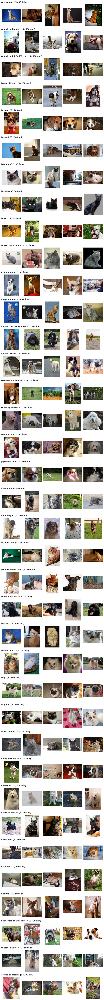

In [60]:
visualize.show_class_samples(v_test, n=5, n_cols=5)

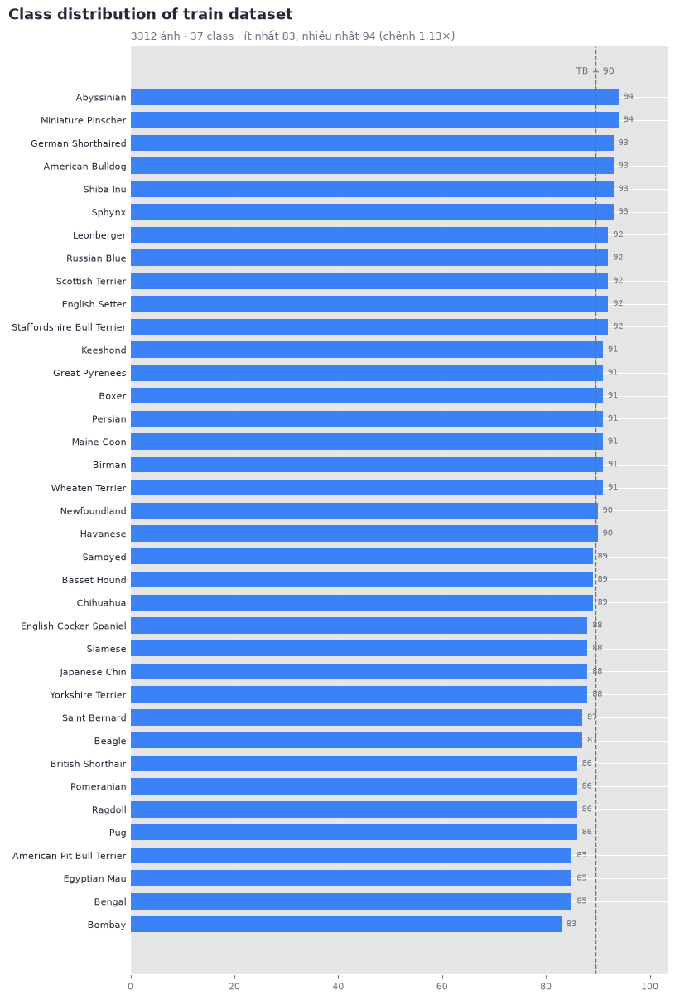

{'Abyssinian': 94,
 'Miniature Pinscher': 94,
 'German Shorthaired': 93,
 'American Bulldog': 93,
 'Shiba Inu': 93,
 'Sphynx': 93,
 'Leonberger': 92,
 'Russian Blue': 92,
 'Scottish Terrier': 92,
 'English Setter': 92,
 'Staffordshire Bull Terrier': 92,
 'Keeshond': 91,
 'Great Pyrenees': 91,
 'Boxer': 91,
 'Persian': 91,
 'Maine Coon': 91,
 'Birman': 91,
 'Wheaten Terrier': 91,
 'Newfoundland': 90,
 'Havanese': 90,
 'Samoyed': 89,
 'Basset Hound': 89,
 'Chihuahua': 89,
 'English Cocker Spaniel': 88,
 'Siamese': 88,
 'Japanese Chin': 88,
 'Yorkshire Terrier': 88,
 'Saint Bernard': 87,
 'Beagle': 87,
 'British Shorthair': 86,
 'Pomeranian': 86,
 'Ragdoll': 86,
 'Pug': 86,
 'American Pit Bull Terrier': 85,
 'Egyptian Mau': 85,
 'Bengal': 85,
 'Bombay': 83}

In [61]:
visualize.plot_class_distribution(v_train, title="Class distribution of train dataset")

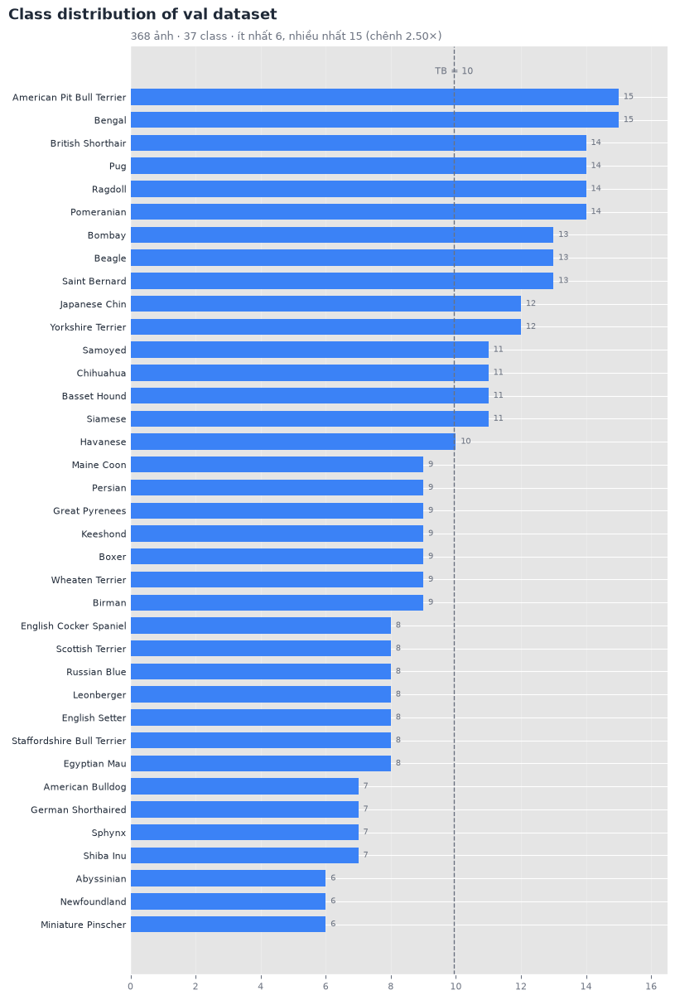

{'American Pit Bull Terrier': 15,
 'Bengal': 15,
 'British Shorthair': 14,
 'Pug': 14,
 'Ragdoll': 14,
 'Pomeranian': 14,
 'Bombay': 13,
 'Beagle': 13,
 'Saint Bernard': 13,
 'Japanese Chin': 12,
 'Yorkshire Terrier': 12,
 'Samoyed': 11,
 'Chihuahua': 11,
 'Basset Hound': 11,
 'Siamese': 11,
 'Havanese': 10,
 'Maine Coon': 9,
 'Persian': 9,
 'Great Pyrenees': 9,
 'Keeshond': 9,
 'Boxer': 9,
 'Wheaten Terrier': 9,
 'Birman': 9,
 'English Cocker Spaniel': 8,
 'Scottish Terrier': 8,
 'Russian Blue': 8,
 'Leonberger': 8,
 'English Setter': 8,
 'Staffordshire Bull Terrier': 8,
 'Egyptian Mau': 8,
 'American Bulldog': 7,
 'German Shorthaired': 7,
 'Sphynx': 7,
 'Shiba Inu': 7,
 'Abyssinian': 6,
 'Newfoundland': 6,
 'Miniature Pinscher': 6}

In [62]:
visualize.plot_class_distribution(v_val, title="Class distribution of val dataset")

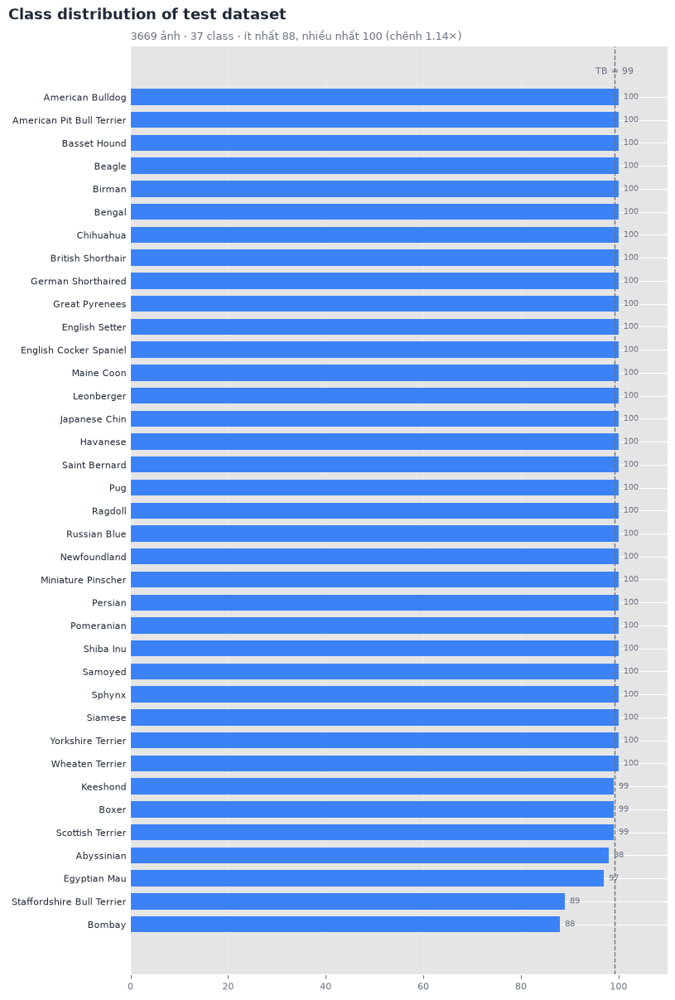

{'American Bulldog': 100,
 'American Pit Bull Terrier': 100,
 'Basset Hound': 100,
 'Beagle': 100,
 'Birman': 100,
 'Bengal': 100,
 'Chihuahua': 100,
 'British Shorthair': 100,
 'German Shorthaired': 100,
 'Great Pyrenees': 100,
 'English Setter': 100,
 'English Cocker Spaniel': 100,
 'Maine Coon': 100,
 'Leonberger': 100,
 'Japanese Chin': 100,
 'Havanese': 100,
 'Saint Bernard': 100,
 'Pug': 100,
 'Ragdoll': 100,
 'Russian Blue': 100,
 'Newfoundland': 100,
 'Miniature Pinscher': 100,
 'Persian': 100,
 'Pomeranian': 100,
 'Shiba Inu': 100,
 'Samoyed': 100,
 'Sphynx': 100,
 'Siamese': 100,
 'Yorkshire Terrier': 100,
 'Wheaten Terrier': 100,
 'Keeshond': 99,
 'Boxer': 99,
 'Scottish Terrier': 99,
 'Abyssinian': 98,
 'Egyptian Mau': 97,
 'Staffordshire Bull Terrier': 89,
 'Bombay': 88}

In [63]:
visualize.plot_class_distribution(v_test, title="Class distribution of test dataset")

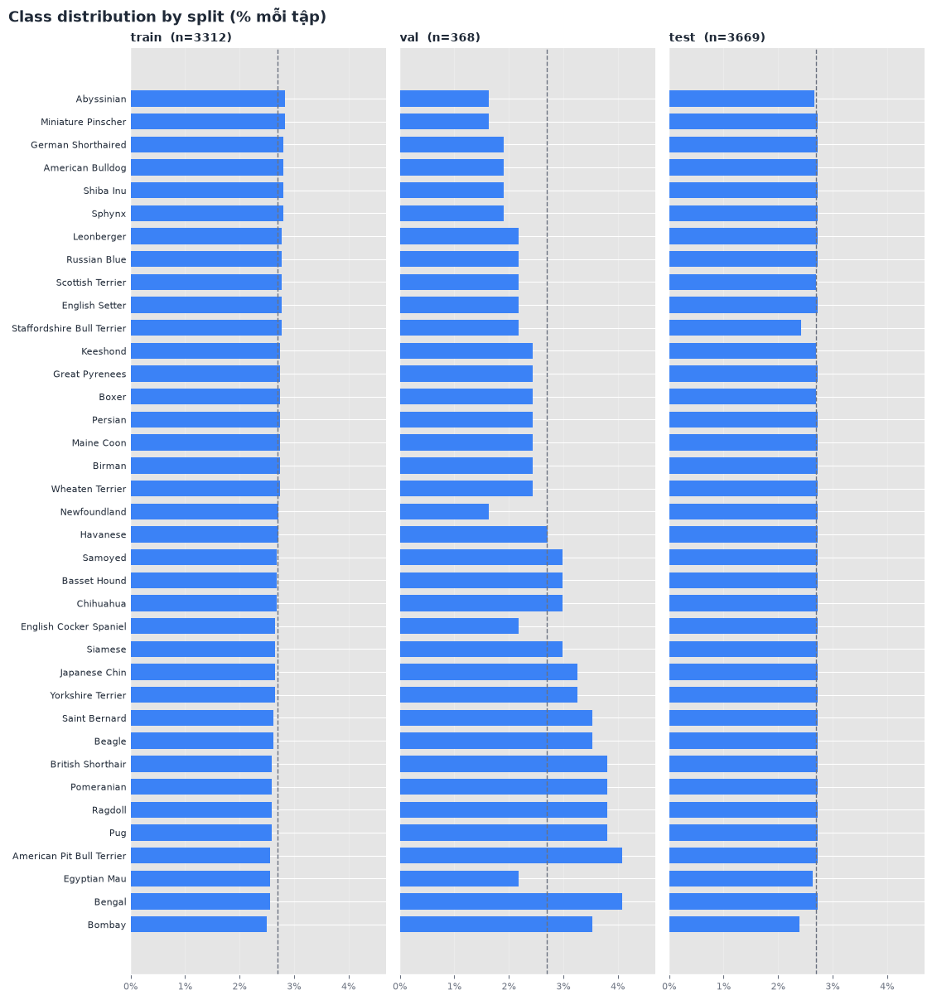

In [64]:
visualize.plot_split_class_distribution({"train": v_train, "val": v_val, "test": v_test},)

## 3.3 Data loader


In [65]:
## Loader
v_train_loader, v_val_loader, v_test_loader = loader_train_val_test(v_train, v_val, v_test)
log.dataloader_log_v2(
    20,
    v_train_loader=v_train_loader,
    v_val_loader=v_val_loader,
    v_test_loader=v_test_loader
)


Number of Pv_train_l: 103
Number of Pv_val_loa: 12
Number of Pv_test_lo: 115



## 4. Kiến trúc
**ResNet18 `weights=None`** (khởi tạo ngẫu nhiên). Cùng kiến trúc với bản transfer learning, chỉ khác có/không pre-trained, nên tách được riêng ảnh hưởng của pre-trained weights.


In [66]:
v_model = resnet18(weights=None).to(config.DEVICE)
v_loss_func = nn.CrossEntropyLoss()
v_optimizer = optim.Adam(v_model.parameters(), lr=config.LR)

# Metadata
print(v_model)
summary(v_model, (3, 224, 224))

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

Layer (type:depth-idx)                   Output Shape              Param #
├─Conv2d: 1-1                            [-1, 64, 112, 112]        9,408
├─BatchNorm2d: 1-2                       [-1, 64, 112, 112]        128
├─ReLU: 1-3                              [-1, 64, 112, 112]        --
├─MaxPool2d: 1-4                         [-1, 64, 56, 56]          --
├─Sequential: 1-5                        [-1, 64, 56, 56]          --
|    └─BasicBlock: 2-1                   [-1, 64, 56, 56]          --
|    |    └─Conv2d: 3-1                  [-1, 64, 56, 56]          36,864
|    |    └─BatchNorm2d: 3-2             [-1, 64, 56, 56]          128
|    |    └─ReLU: 3-3                    [-1, 64, 56, 56]          --
|    |    └─Conv2d: 3-4                  [-1, 64, 56, 56]          36,864
|    |    └─BatchNorm2d: 3-5             [-1, 64, 56, 56]          128
|    |    └─ReLU: 3-6                    [-1, 64, 56, 56]          --
|    └─BasicBlock: 2-2                   [-1, 64, 56, 56]          --
|

**Lưu ý:** Thông số kiến trúc model trên có output class là 1000.

In [67]:
v_model.fc = nn.Linear(in_features=512, out_features=len(v_test.classes)).to(config.DEVICE)
# Check again the model
print(v_model)
summary(v_model, (3, 224, 224))

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

Layer (type:depth-idx)                   Output Shape              Param #
├─Conv2d: 1-1                            [-1, 64, 112, 112]        9,408
├─BatchNorm2d: 1-2                       [-1, 64, 112, 112]        128
├─ReLU: 1-3                              [-1, 64, 112, 112]        --
├─MaxPool2d: 1-4                         [-1, 64, 56, 56]          --
├─Sequential: 1-5                        [-1, 64, 56, 56]          --
|    └─BasicBlock: 2-1                   [-1, 64, 56, 56]          --
|    |    └─Conv2d: 3-1                  [-1, 64, 56, 56]          36,864
|    |    └─BatchNorm2d: 3-2             [-1, 64, 56, 56]          128
|    |    └─ReLU: 3-3                    [-1, 64, 56, 56]          --
|    |    └─Conv2d: 3-4                  [-1, 64, 56, 56]          36,864
|    |    └─BatchNorm2d: 3-5             [-1, 64, 56, 56]          128
|    |    └─ReLU: 3-6                    [-1, 64, 56, 56]          --
|    └─BasicBlock: 2-2                   [-1, 64, 56, 56]          --
|

Đổi lại output classes thành 37 phù hợp với OxfordIIIpets dataset

# 5. Training

In [68]:
# Resume weight
v_start_epoch, v_best_val = utility.resume_weight(SAVE_WEIGHT, v_model, v_optimizer)
log.print_log("Best accuracy", v_best_val)
log.print_log("Start epoch", v_start_epoch)


# Train
list_metric_train_epoch, list_metric_eval_epoch = training_phase(
    v_model,
    v_loss_func,
    v_optimizer,
    v_train_loader,
    v_val_loader,
    SAVE_WEIGHT,
    config.EPOCH,
    v_start_epoch,
    WRITER,
    classes=v_test.classes,
    p_best_val= v_best_val
)

No found weight. Train from start
Best accuracy       : 0.0


  0%|          | 0/103 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]


Accuracy enhanced   : 0.0 -> 0.05434782608695652
Save weights: weights/resnet18_baseline.pt


  0%|          | 0/103 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

... (70 outputs left out)

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/103 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]


Accuracy enhanced   : 0.30434782608695654 -> 0.33152173913043476
Save weights: weights/resnet18_baseline.pt


# 6. Evaluate

In [69]:
v_obj_eval_metric = test_phase(v_model, v_test_loader, WRITER)

================================ Test phase ================================


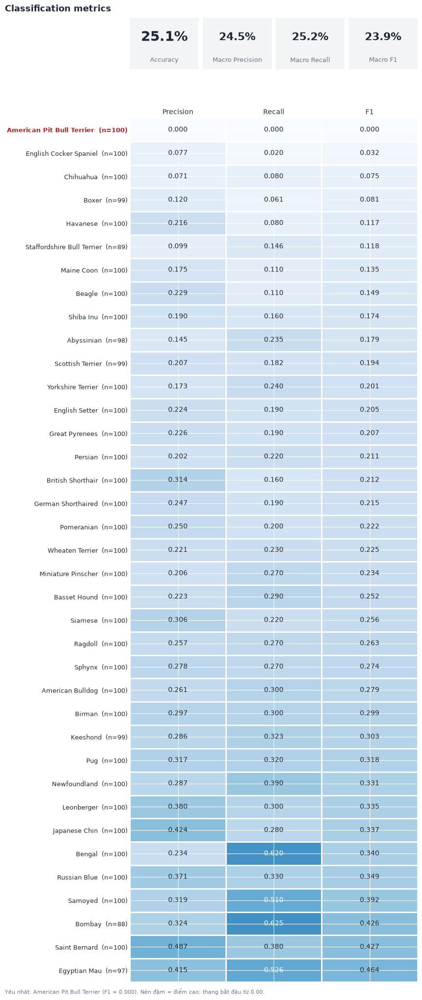

{'accuracy': 0.2510220768601799,
 'precision': array([0.14465409, 0.26086957, 0.        , 0.22307692, 0.22916667,
        0.23396226, 0.2970297 , 0.32352941, 0.12      , 0.31372549,
        0.07079646, 0.41463415, 0.07692308, 0.22352941, 0.24675325,
        0.22619048, 0.21621622, 0.42424242, 0.28571429, 0.37974684,
        0.17460317, 0.20610687, 0.28676471, 0.20183486, 0.25      ,
        0.31683168, 0.25714286, 0.37078652, 0.48717949, 0.31875   ,
        0.20689655, 0.19047619, 0.30555556, 0.27835052, 0.09923664,
        0.22115385, 0.17266187]),
 'recall': array([0.23469388, 0.3       , 0.        , 0.29      , 0.11      ,
        0.62      , 0.3       , 0.625     , 0.06060606, 0.16      ,
        0.08      , 0.5257732 , 0.02      , 0.19      , 0.19      ,
        0.19      , 0.08      , 0.28      , 0.32323232, 0.3       ,
        0.11      , 0.27      , 0.39      , 0.22      , 0.2       ,
        0.32      , 0.27      , 0.33      , 0.38      , 0.51      ,
        0.18181818, 0.16  

In [70]:
visualize.plot_classification_metrics(
    v_obj_eval_metric.list_actual,
    v_obj_eval_metric.list_prediction,
    v_test.classes,
)

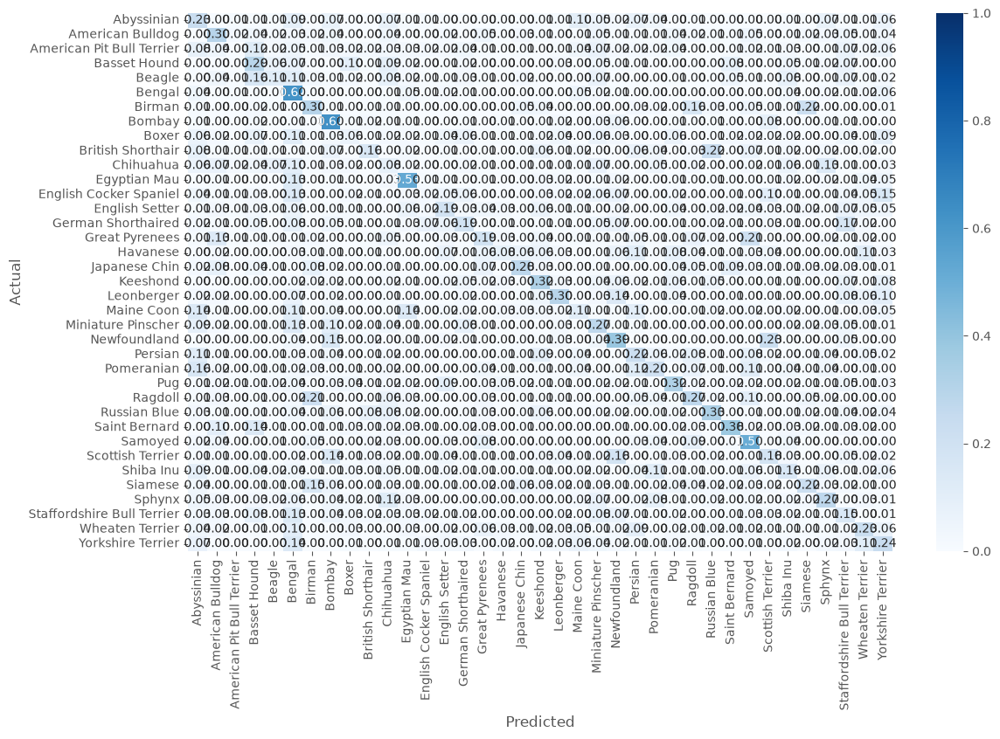

In [71]:
v_cf_matrix = v_obj_eval_metric.get_fig_cf_matrix(v_test.classes)